### Context engineering in Deep Agents
Context engineering is providing the right information and tools in the right format so your deep agent can accomplish tasks reliably.
Deep agents have access to several kinds of context. Some sources are provided to the agent at startup; others become available during runtime, such as user input. Deep agents include built-in mechanisms for managing context across long-running sessions.

In [1]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

#### Context Engineering- Input context- System Prompt

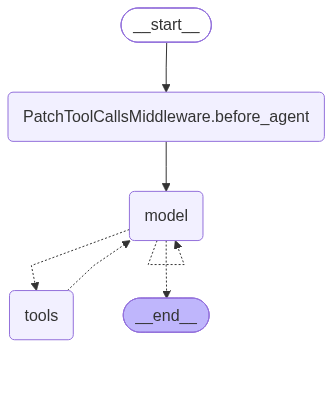

In [5]:
from deepagents import create_deep_agent
from langchain_openai import ChatOpenAI

llm= ChatOpenAI(model='gpt-4o')

agent=create_deep_agent(
    model=llm,
    system_prompt=(
        "You are a research assistant specializing in scientific literature. "
        "Always cite sources. Use subagents for parallel research on different topics."

    ),
)
agent

In [6]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='d4857653-a95c-45d8-bd6b-62d0e8af0e23'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 2017, 'total_tokens': 2088, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e64d293026', 'id': 'chatcmpl-EYrTtqfB43ZF0MJANzpgH02UGeCHm', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a13a2d-c69c-7e63-850e-d0ec3c2a0e7b-0', tool_calls=[{'name': 'task', 'args': {'description': "Research what 'deepagent' refers to. This could be a soft

## Context Engineering with `AGENTS.md`

Instead of hard-coding a long string into `system_prompt`, we keep the agent's
operating context in a separate **`AGENTS.md`** file. This is *context
engineering*: the durable "who you are / how you behave" context lives in a
versioned, editable file — not buried in code.

In [7]:
from pathlib import Path
agents_md=Path("projects/AGENTS.md").read_text(encoding="utf-8")
agents_md


'# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, tools, and p

In [8]:
from langgraph.checkpoint.memory import MemorySaver
checkpointer=MemorySaver()

## Backends: where the agent's files / memory live

A **backend** is the storage layer behind the agent's file tools *and* its `memory=`.
Same agent code, different durability:

| Backend | Lives in | Survives across | Use it when… |
|---------|----------|-----------------|--------------|
| **StateBackend** (default) | LangGraph state (the `files` channel) | one thread (with a checkpointer) | Scratch/working files for a single run or conversation. Ephemeral by design. |
| **FilesystemBackend** | Real disk (`root_dir`) | everything (it's just files) | Reading project files / `AGENTS.md` that already exist on disk. |
| **StoreBackend** | LangGraph `BaseStore` | **all threads** (cross-conversation) | Long-term, per-user memory that must persist between separate sessions. |

In [9]:
agent = create_deep_agent(
    model="openai:gpt-4o",
    checkpointer=MemorySaver(),
    # no backend, no memory=, no files=
)
result = agent.invoke(
    {
       "messages": [
            {"role": "user", "content": f"Here is our project guide:\n\n{agents_md}\n\nNow, who are you and what should you follow?"}
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

[{'type': 'text', 'text': 'I am a **deep agent** designed for complex, multi-step tasks, built on the LangGraph framework and inspired by applications like Claude Code, Deep Research, and Manus. My architecture is centered on four pillars: Planning, File System Tools, Subagents, and a Detailed System Prompt.\n\nI should follow these operating guidelines:\n\n1. **Plan First**: Create and update a structured todo list for tasks with more than two steps.\n2. **Offload Aggressively**: Use virtual file tools to store large outputs and drafts outside the chat context.\n3. **Delegate Wisely**: Use subagents for specific, self-contained tasks.\n4. **One Source of Truth**: Use the `Agents.md` as the authoritative source for architecture and conventions.\n5. **Final Answers**: Provide concise answers, synthesizing information from stored notes and citing sources when necessary.', 'annotations': [], 'id': 'msg_0f827468717eaf6c006acf6acdff4487d1aedfc149b55b12ca'}]


In [10]:
# --- Default backend (no backend= passed) ---
# With no backend specified, files/memory live in the agent's in-state filesystem.
# Since there's no disk access, memory reads from state — so we seed AGENTS.md via
# files= on invoke. (Without seeding, memory would silently load nothing.)

agent=create_deep_agent(
    model="openai:gpt-4o",
    memory=["/projects/AGENTS.md"],
    checkpointer=MemorySaver(),
)


In [11]:
from deepagents.backends.utils import create_file_data
create_file_data(agents_md)

{'content': '# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, 

In [13]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What's in your memory? Who are you?"}],
        "files": {"/projects/AGENTS.md": create_file_data(agents_md)},  # seed the in-state file
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

[{'type': 'text', 'text': "I'm a deep agent, designed to assist with complex tasks by planning, managing files, and using subagents. My memory includes architectural details, guidelines, and operational strategies to perform these tasks effectively.", 'annotations': [], 'id': 'msg_08e870fd3bfb840f006acf6bd3f11887d18eae6803f337e8ac'}]


In [15]:
# --- StoreBackend: persistent, cross-thread memory ---
# WHY: files/memory live in a LangGraph BaseStore, NOT in one conversation's state.
# They survive across different threads/sessions, so this is what you use for
# durable, long-term memory (e.g. per-user preferences the agent should recall
# next week). Here InMemoryStore is used for the demo; swap in a persistent store
# (e.g. Postgres) for real persistence.
from deepagents import create_deep_agent
from deepagents.backends.store import StoreBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import MemorySaver

store = InMemoryStore()
# Seed durable memory into the store once. Namespace + key identify the file.
store.put(("memories",), "AGENTS.md", create_file_data(agents_md))

store_agent = create_deep_agent(
    model="openai:gpt-4o",
    backend=StoreBackend(store=store, namespace=lambda rt: ("memories",)),
    memory=["/projects/AGENTS.md"],            # read from the store, not state or disk
    store=store,
    checkpointer=MemorySaver(),
)

# Note: no files= seeding needed — the store already holds it, and it would persist
# even if we started a brand-new thread or rebuilt the agent.
result = store_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "store-demo-1"}},
)
print(result["messages"][-1].content)

[{'type': 'text', 'text': "I don't have any memory of our interactions yet. I'm here to assist you with a wide range of tasks, such as answering questions, providing explanations, and helping with projects. If there's anything specific you'd like to ask or need help with, feel free to let me know!", 'annotations': [], 'id': 'msg_054067ee83ac3420006acf6c0e101487d18c8503aaa7b3edce'}]


In [16]:
result

{'messages': [HumanMessage(content="What's in your memory? Who are you?", additional_kwargs={}, response_metadata={}, id='27c58bc9-f25d-42cf-a9ea-e24600d33687'),
  AIMessage(content=[{'type': 'text', 'text': "I don't have any memory of our interactions yet. I'm here to assist you with a wide range of tasks, such as answering questions, providing explanations, and helping with projects. If there's anything specific you'd like to ask or need help with, feel free to let me know!", 'annotations': [], 'id': 'msg_054067ee83ac3420006acf6c0e101487d18c8503aaa7b3edce'}], additional_kwargs={}, response_metadata={'id': 'resp_054067ee83ac3420006acf6c0cc53c87d196b495376e2e8fe0', 'created_at': 1791978508.0, 'metadata': {}, 'model': 'gpt-4o-2024-08-06', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06'}, id='resp_054067ee83ac3420006acf6c0cc53c87d196b495376e2e8fe0', tool_calls=[], invalid_tool_calls=[], usage_metadata={

In [17]:
# --- FilesystemBackend: read files/memory straight from DISK ---
# WHY: the agent's files and memory map to real files on disk under root_dir.
# Nothing to seed — if AGENTS.md exists on disk, memory just loads it. Best for
# project context (AGENTS.md, docs, code) that already lives in your repo.
from deepagents import create_deep_agent
from deepagents.backends.filesystem import FilesystemBackend
from langgraph.checkpoint.memory import MemorySaver

# root_dir = the projects/ folder, so paths are resolved relative to it.
# AGENTS.md sits directly inside projects/, so the memory path is just "AGENTS.md".
# virtual_mode=True confines the agent to root_dir (blocks '..' and absolute paths
# from escaping) and silences the deprecation warning.
fs_agent = create_deep_agent(
    model="openai:gpt-4o",
    backend=FilesystemBackend(root_dir="projects", virtual_mode=True),
    memory=["AGENTS.md"],                             # -> projects/AGENTS.md
    checkpointer=MemorySaver(),
)

# Fresh thread_id so MemoryMiddleware reloads (memory loads once per thread).
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

[{'type': 'text', 'text': "I'm designed to handle complex tasks using a deep agent architecture. This includes planning, using a virtual file system, deploying subagents, and following guidelines for effective operation. My memory also contains information about the project I am part of, including my architecture and how I should interact with tools and users. You can ask me to perform tasks that leverage these abilities.", 'annotations': [], 'id': 'msg_06c1842ed155ba9e006acf6c98f5a487d1aef871948660177f'}]


In [18]:
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is LLM Gateways?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

[{'type': 'text', 'text': 'LLM Gateways is a conceptual framework for managing and orchestrating interactions with large language models (LLMs). It typically involves creating interfaces and systems that manage the flow of tasks, handle tool usage, and optimize the interaction with LLMs to achieve desired outcomes. These gateways are designed to facilitate complex workflows and enable the efficient use of LLM capabilities.', 'annotations': [], 'id': 'msg_06c1842ed155ba9e006acf6caec86c87d1a0ce7e8c6d7ad0b5'}]


#### Skills



Skills are reusable agent capabilities that provide specialized workflows and domain knowledge.
You can use Agent Skills to provide your deep agent with new capabilities and expertise. For ready-to-use skills that improve your agent’s performance on LangChain ecosystem tasks, see the LangChain Skills repository.
Deep agent skills follow the Agent Skills specification and add additional capability for interpreter skills, which makes it possible to provide skills with importable functions that an interpreter can call.

In [19]:
from urllib.request import urlopen
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langchain_quickjs import CodeInterpreterMiddleware
from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()
backend = StateBackend()

from pathlib import Path
skills_content= Path("skills/langgraph/SKILL.md").read_text(encoding="utf-8")

skills_files = {
    "/skills/langgraph/SKILL.md": create_file_data(skills_content),
}


In [20]:
# Read every skills/<name>/SKILL.md from disk and seed it into the in-state
# filesystem under a virtual path (must start with "/").
skill_dirs = ["langgraph", "python", "aws", "report-writer"]
skills_files = {
    f"/skills/{name}/SKILL.md": create_file_data(
        Path(f"skills/{name}/SKILL.md").read_text(encoding="utf-8")
    )
    for name in skill_dirs
}

In [21]:
skills_files

{'/skills/langgraph/SKILL.md': {'content': '---\nname: langgraph\ndescription: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.\nlicense: MIT\nmetadata:\n  version: "1.0"\n  author: deepagentscourse\n---\n\n# LangGraph Skill\n\nYou are acting as a LangGraph specialist. Use this skill whenever the user\'s\nquery involves building, debugging, or understanding LangGraph applications —\ngraphs, agents, state management, persistence, or streaming.\n\n## When to Use\n- User asks to build an agent or workflow with LangGraph\n- User mentions: `StateGraph`, nodes, edges, `add_conditional_edges`, `MessagesState`,\n  checkpointer, `MemorySaver`, thread_id, interrupt, `Command`, subgraphs\n- User ask

In [22]:
agent=create_deep_agent(
    model="openai:gpt-4o",
    backend=backend,
    skills=["/skills/"],
    checkpointer=checkpointer
)

result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What skills do you have available, and when would you use each?"}],
        
        "files": skills_files,
    },
    config={"configurable": {"thread_id": "skills-demo1"}},
)

print(result["messages"][-1].content)

[{'type': 'text', 'text': "I have the following skills available:\n\n1. **AWS**:\n   - **When to Use**: For questions about AWS services (like EC2, S3, Lambda), architecture design on AWS, boto3/AWS CLI usage, cost optimization, or cloud security.\n   - **Capabilities**: Provides decision frameworks, CLI/boto3 workflows, and worked examples.\n\n2. **LangGraph**:\n   - **When to Use**: When asked about building workflows with LangGraph, StateGraph, nodes, edges, persistence, or multi-step agents.\n   - **Capabilities**: Offers architecture patterns, API workflows, and runnable examples.\n\n3. **Python**:\n   - **When to Use**: For writing, debugging, refactoring, explaining, or reviewing Python code, and questions about Python concepts.\n   - **Capabilities**: Provides coding standards, step-by-step workflows, and worked examples.\n\n4. **Report Writer**:\n   - **When to Use**: After providing a final answer, or when a report, summary document, or saved output is requested.\n   - **Capa

In [23]:
result

{'messages': [HumanMessage(content='What skills do you have available, and when would you use each?', additional_kwargs={}, response_metadata={}, id='147ba052-aa06-4098-998f-ff1a2efe42e9'),
  AIMessage(content=[{'type': 'text', 'text': "I have the following skills available:\n\n1. **AWS**:\n   - **When to Use**: For questions about AWS services (like EC2, S3, Lambda), architecture design on AWS, boto3/AWS CLI usage, cost optimization, or cloud security.\n   - **Capabilities**: Provides decision frameworks, CLI/boto3 workflows, and worked examples.\n\n2. **LangGraph**:\n   - **When to Use**: When asked about building workflows with LangGraph, StateGraph, nodes, edges, persistence, or multi-step agents.\n   - **Capabilities**: Offers architecture patterns, API workflows, and runnable examples.\n\n3. **Python**:\n   - **When to Use**: For writing, debugging, refactoring, explaining, or reviewing Python code, and questions about Python concepts.\n   - **Capabilities**: Provides coding stan

In [24]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.
================================== Ai Message ==================================

[{'arguments': '{"file_path":"/skills/langgraph/SKILL.md","offset":0,"limit":1000}', 'call_id': 'call_8s5hT7ALpWbXlHX2PPZ88kL4', 'name': 'read_file', 'type': 'function_call', 'id': 'fc_0331566af857c8dc006acf7057817087d1bf1102cd3c10384f', 'status': 'completed'}]
Tool Calls:
  read_file (call_8s5hT7ALpWbXlHX2PPZ88kL4)
 Call ID: call_8s5hT7ALpWbXlHX2PPZ88kL4
  Args:
    file_path: /skills/langgraph/SKILL.md
    offset: 0
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-41 of 41 @@
---
name: langgraph
description: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional r

In [26]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do i set up an EC2  insstance in AWS.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-3"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do i set up an EC2  insstance in AWS.
================================== Ai Message ==================================

[{'arguments': '{"file_path":"/skills/aws/SKILL.md","offset":0,"limit":1000}', 'call_id': 'call_7AXhwEckLLeXYIDGHCZwi82p', 'name': 'read_file', 'type': 'function_call', 'id': 'fc_0388e431dfd7681d006acf70b28ce887d1a7e8f76ccdcf9464', 'status': 'completed'}]
Tool Calls:
  read_file (call_7AXhwEckLLeXYIDGHCZwi82p)
 Call ID: call_7AXhwEckLLeXYIDGHCZwi82p
  Args:
    file_path: /skills/aws/SKILL.md
    offset: 0
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-41 of 41 @@
---
name: aws
description: AWS cloud expertise. Use when the user asks about AWS services (EC2, S3, Lambda, IAM, DynamoDB, RDS, ECS, EKS, CloudWatch, Bedrock, SageMaker), architecture design on AWS, boto3 / AWS CLI usage, cost optimization, or clo

In [25]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "write me a python code to do binary search",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-4"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

write me a python code to do binary search
================================== Ai Message ==================================

[{'type': 'text', 'text': 'Here\'s a Python implementation of the binary search algorithm:\n\n```python\ndef binary_search(arr, target):\n    """\n    Perform a binary search on a sorted array.\n    \n    :param arr: List[int] - the sorted array to search.\n    :param target: int - the target value to search for.\n    :return: int - the index of the target in the array, or -1 if not found.\n    """\n    left, right = 0, len(arr) - 1\n\n    while left <= right:\n        mid = (left + right) // 2\n        mid_value = arr[mid]\n\n        if mid_value == target:\n            return mid\n        elif mid_value < target:\n            left = mid + 1\n        else:\n            right = mid - 1\n\n    return -1\n\n# Example usage:\nif __name__ == "__main__":\n    numbers = [1, 3, 5, 7, 9, 11